In [ ]:
#@title 1. MONTAR EL DRIVE  (If you are in in colab){ display-mode: "form" }
import os
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content/drive/My Drive/ai-2-uis-student')
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/ai-2-uis-student


In [ ]:
#@title Importar librerías
import tensorflow as tf
from tensorflow.keras import layers
import time
import matplotlib.pyplot as plt
from IPython import display
import os
import PIL
from ipywidgets import interact, widgets
import numpy as np


In [ ]:
#@title Cargar y preparar datos
print(" Cargando Fashion-MNIST...")
(train_images, train_labels), _ = tf.keras.datasets.fashion_mnist.load_data()

# Preprocesar
train_images = train_images.reshape(-1, 28, 28, 1).astype('float32')
train_images = (train_images - 127.5) / 127.5

# Crear dataset
BATCH_SIZE = 128
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))
train_dataset = train_dataset.shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)  # drop_remainder=True

print(f"✓ Dataset: {train_images.shape}")
print(f"✓ Rango: [{train_images.min()}, {train_images.max()}]")
print(f"✓ Batches con drop_remainder=True (descarta último batch incompleto)")

📥 Cargando Fashion-MNIST...
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
✓ Dataset: (60000, 28, 28, 1)
✓ Rango: [-1.0, 1.0]
✓ Batches con drop_remainder=True (descarta último batch incompleto)


In [ ]:
#@title Configuración
noise_dim = 100
num_classes = 10
embedding_dim = 50

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

In [ ]:
#@title Generador
def make_conditional_generator():
    noise_input = layers.Input(shape=(noise_dim,))
    label_input = layers.Input(shape=(1,))

    label_embedding = layers.Embedding(num_classes, embedding_dim)(label_input)
    label_embedding = layers.Flatten()(label_embedding)

    concat = layers.Concatenate()([noise_input, label_embedding])

    x = layers.Dense(7*7*512, use_bias=False)(concat)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Reshape((7, 7, 512))(x)

    x = layers.Conv2DTranspose(256, (5, 5), strides=(2, 2),
                               padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2DTranspose(128, (5, 5), strides=(2, 2),
                               padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)

    output = layers.Conv2D(1, (3, 3), padding='same',
                           use_bias=False, activation='tanh')(x)

    return tf.keras.Model([noise_input, label_input], output, name='generator')



In [ ]:
#@title Discriminador
def make_conditional_discriminator():
    image_input = layers.Input(shape=(28, 28, 1))
    label_input = layers.Input(shape=(1,))

    label_embedding = layers.Embedding(num_classes, 28*28)(label_input)
    label_embedding = layers.Flatten()(label_embedding)
    label_embedding = layers.Reshape((28, 28, 1))(label_embedding)

    concat = layers.Concatenate()([image_input, label_embedding])

    x = layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same')(concat)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same')(x)
    x = layers.LayerNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv2D(256, (5, 5), strides=(2, 2), padding='same')(x)
    x = layers.LayerNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Conv2D(512, (3, 3), strides=(1, 1), padding='same')(x)
    x = layers.LayerNormalization()(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(128)(x)
    x = layers.LeakyReLU(alpha=0.2)(x)
    output = layers.Dense(1)(x)

    return tf.keras.Model([image_input, label_input], output, name='discriminator')


In [ ]:
#@title Funciones de pérdida
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output, label_smoothing=0.1):
    real_loss = cross_entropy(
        tf.ones_like(real_output) * (1 - label_smoothing),
        real_output
    )
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

# Optimizadores
generator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5, beta_2=0.999)
discriminator_optimizer = tf.keras.optimizers.Adam(0.0002, beta_1=0.5, beta_2=0.999)


In [ ]:
#@title Paso de entrenamiento
@tf.function
def train_step(images, labels):
    # CRÍTICO: Usar el batch_size real del batch actual, no BATCH_SIZE constante
    batch_size = tf.shape(images)[0]
    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator([noise, labels], training=True)

        real_output = discriminator([images, labels], training=True)
        fake_output = discriminator([generated_images, labels], training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

    return gen_loss, disc_loss


In [ ]:
#@title Funciones de utilidad
def setup_directories():
    dirs = ['/content/drive/My Drive/code/training_checkpoints', '/content/drive/My Drive/imgs/cgan_fashion', '/content/drive/My Drive/imgs/cgan_samples']
    for d in dirs:
        os.makedirs(d, exist_ok=True)
    print(f"✓ Directorios: {', '.join(dirs)}")

def generate_and_save_images(model, epoch, test_noise, test_labels, save=True, show=True):
    predictions = model([test_noise, test_labels], training=False)

    fig = plt.figure(figsize=(10, 10))
    for i in range(min(16, predictions.shape[0])):
        plt.subplot(4, 4, i+1)
        img = predictions[i, :, :, 0] * 127.5 + 127.5
        plt.imshow(img, cmap='gray')
        class_idx = int(test_labels[i][0])
        plt.title(class_names[class_idx], fontsize=9)
        plt.axis('off')

    plt.suptitle(f'Época {epoch}', fontsize=14, y=0.98)
    plt.tight_layout()

    if save:
        plt.savefig(f'/content/drive/My Drive/imgs/cgan_fashion/image_at_epoch_{epoch:04d}.png',
                   dpi=100, bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()

def plot_training_history(history):
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history['epochs'], history['gen_loss'], label='Generator', linewidth=2)
    plt.plot(history['epochs'], history['disc_loss'], label='Discriminator', linewidth=2)
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.title('Pérdidas durante Entrenamiento')
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(1, 2, 2)
    plt.plot(history['epochs'], history['gen_loss'], linewidth=2)
    plt.xlabel('Época')
    plt.ylabel('Pérdida Generador')
    plt.title('Evolución del Generador')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('/content/drive/My Drive/imgs/cgan_samples/training_history.png', dpi=150)
    plt.show()

In [ ]:
#@title Función de entrenamiento
def train(dataset, epochs, save_every=5, checkpoint_every=15, show_progress=True):
    history = {'gen_loss': [], 'disc_loss': [], 'epochs': []}

    print("🚀 Iniciando entrenamiento...")
    print(f"   Épocas: {epochs} | Guardar cada: {save_every} | Checkpoint cada: {checkpoint_every}")
    print("="*60)

    for epoch in range(epochs):
        start = time.time()
        gen_losses, disc_losses = [], []

        for image_batch, label_batch in dataset:
            gen_loss, disc_loss = train_step(image_batch, label_batch)
            gen_losses.append(gen_loss)
            disc_losses.append(disc_loss)

        avg_gen_loss = tf.reduce_mean(gen_losses)
        avg_disc_loss = tf.reduce_mean(disc_losses)

        history['gen_loss'].append(float(avg_gen_loss))
        history['disc_loss'].append(float(avg_disc_loss))
        history['epochs'].append(epoch + 1)

        if (epoch + 1) % save_every == 0 or epoch == 0:
            if show_progress:
                display.clear_output(wait=True)
            generate_and_save_images(generator, epoch + 1, seed, seed_labels, save=True, show=show_progress)

        if (epoch + 1) % checkpoint_every == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
            print(f"💾 Checkpoint guardado: época {epoch + 1}")

        print(f'Época {epoch + 1}/{epochs} | Gen: {avg_gen_loss:.4f} | Disc: {avg_disc_loss:.4f} | {time.time()-start:.2f}s')

        if avg_gen_loss > 10 or avg_disc_loss > 10:
            print("⚠️  Pérdidas muy altas")

    checkpoint.save(file_prefix=checkpoint_prefix)
    print("="*60)
    print("✅ Entrenamiento completado")

    display.clear_output(wait=True)
    generate_and_save_images(generator, epochs, seed, seed_labels)
    plot_training_history(history)

    return history


In [ ]:
#@title Funciones de visualización
def generate_clothing_samples(model, clothing_type, num_samples=9, save=False):
    if clothing_type not in class_names:
        print(f" Opciones: {', '.join(class_names)}")
        return

    class_idx = class_names.index(clothing_type)
    noise = tf.random.normal([num_samples, noise_dim])
    labels = tf.constant([[class_idx]] * num_samples)
    predictions = model([noise, labels], training=False)

    cols = int(num_samples ** 0.5)
    rows = (num_samples + cols - 1) // cols

    fig = plt.figure(figsize=(3*cols, 3*rows))
    for i in range(num_samples):
        plt.subplot(rows, cols, i+1)
        img = predictions[i, :, :, 0] * 127.5 + 127.5
        plt.imshow(img, cmap='gray')
        plt.axis('off')

    plt.suptitle(f'Variaciones: {clothing_type}', fontsize=16)
    plt.tight_layout()

    if save:
        filename = f'/content/drive/My Drive/imgs/cgan_samples/{clothing_type.lower().replace("/", "_")}_samples.png'
        plt.savefig(filename, dpi=150, bbox_inches='tight')
        print(f"✓ Guardado: {filename}")
    plt.show()

def create_image_explorer(folder='/content/drive/My Drive/imgs/cgan_fashion'):
    path = folder
    files = sorted([f for f in os.listdir(path) if f.endswith('.png')])

    if not files:
        print(f"❌ No hay imágenes en {folder}")
        return

    def plot_image(index):
        image_file = os.path.join(path, files[index])
        img = plt.imread(image_file)
        plt.figure(figsize=(10, 10))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f'Época: {files[index]}', fontsize=14)
        plt.show()

    interact(plot_image, index=widgets.IntSlider(min=0, max=len(files)-1, step=1, value=0, description='Época:'))

def compare_epochs(epoch_list, folder='/content/drive/My Drive/imgs/cgan_fashion'):
    n = len(epoch_list)
    fig = plt.figure(figsize=(5*n, 5))

    for i, epoch in enumerate(epoch_list):
        try:
            img = plt.imread(f'{folder}/image_at_epoch_{epoch:04d}.png')
            plt.subplot(1, n, i+1)
            plt.imshow(img)
            plt.title(f'Época {epoch}')
            plt.axis('off')
        except:
            print(f"⚠️  Época {epoch} no encontrada")
    plt.tight_layout()
    plt.show()


In [ ]:
#@title Inicialización
setup_directories()

generator = make_conditional_generator()
discriminator = make_conditional_discriminator()

seed = tf.random.normal([16, noise_dim])
seed_labels = tf.constant([[i % 10] for i in range(16)])

checkpoint_dir = '/content/drive/My Drive/code/training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
    generator=generator,
    discriminator=discriminator
)

print("="*60)
print("✓ CGAN inicializada")
print(f"✓ Generador: {generator.count_params():,} parámetros")
print(f"✓ Discriminador: {discriminator.count_params():,} parámetros")
print(f"\n📦 Categorías:")
for i, name in enumerate(class_names):
    print(f"   {i}: {name}")
print("="*60)

✓ Directorios: /content/drive/My Drive/code/training_checkpoints, /content/drive/My Drive/imgs/cgan_fashion, /content/drive/My Drive/imgs/cgan_samples
✓ CGAN inicializada
✓ Generador: 8,036,148 parámetros
✓ Discriminador: 3,266,273 parámetros

📦 Categorías:
   0: T-shirt/top
   1: Trouser
   2: Pullover
   3: Dress
   4: Coat
   5: Sandal
   6: Shirt
   7: Sneaker
   8: Bag
   9: Ankle boot


/usr/local/lib/python3.12/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


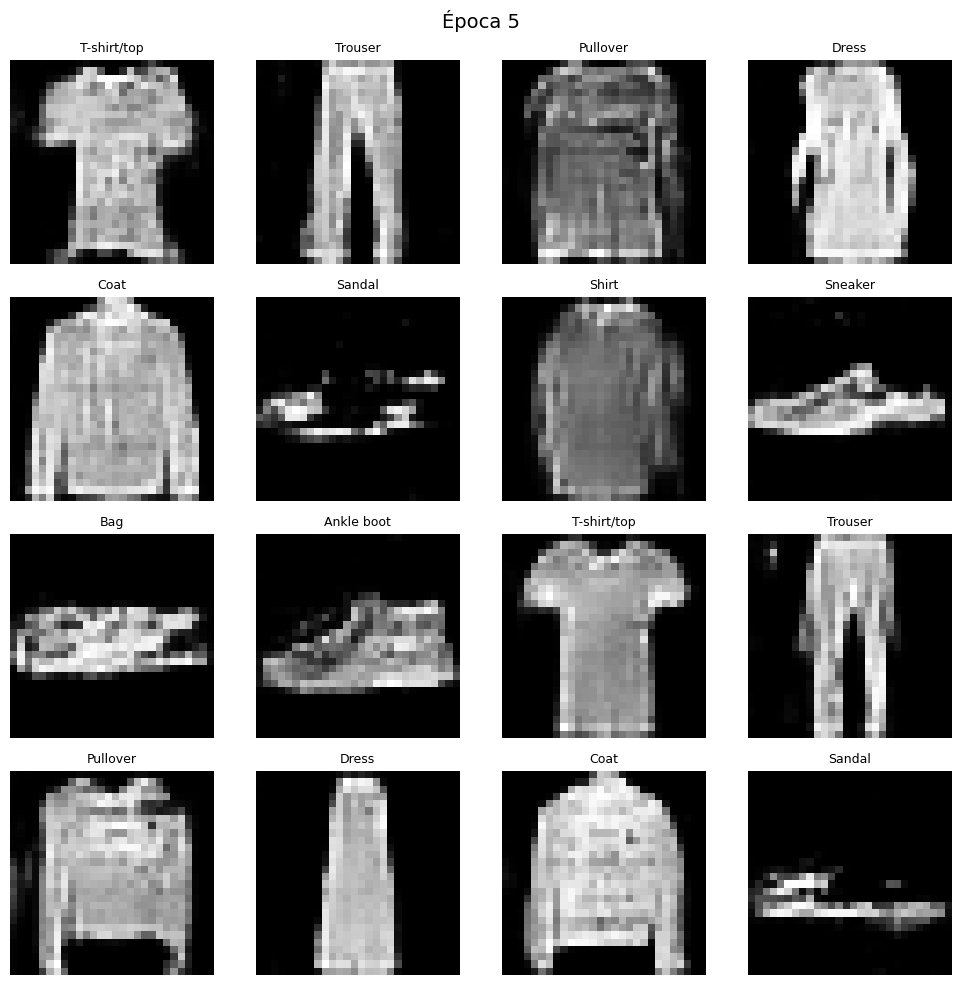

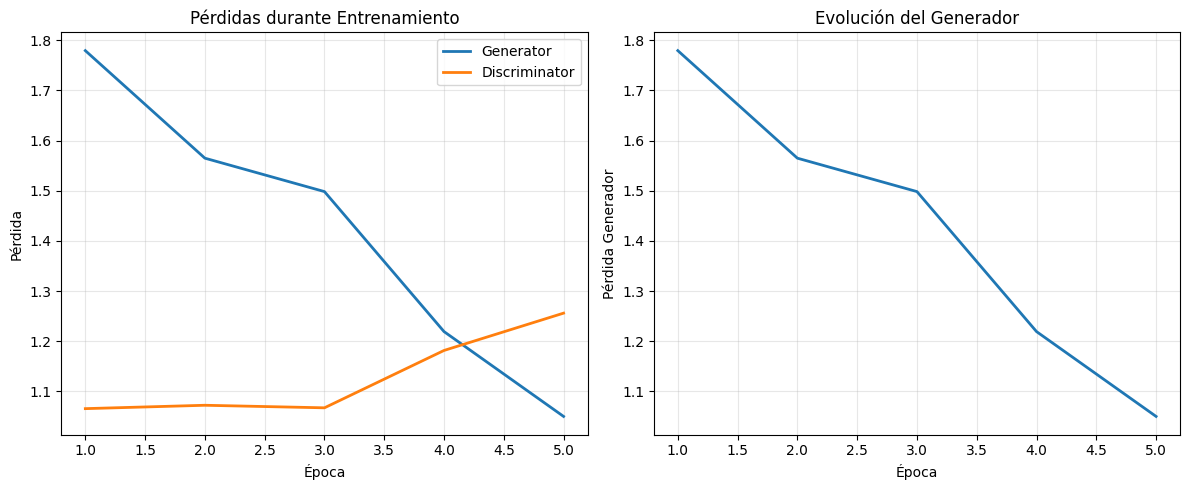

In [ ]:
#@title Prueba Rapida 5 epochs
print("\n🚀 Entrenamiento de prueba (5 épocas)")
history = train(train_dataset, epochs=5, save_every=1, checkpoint_every=5)


In [ ]:
#@title Ver resultados prueba
create_image_explorer()


interactive(children=(IntSlider(value=0, description='Época:', max=23), Output()), _dom_classes=('widget-inter…

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/dress_samples.png


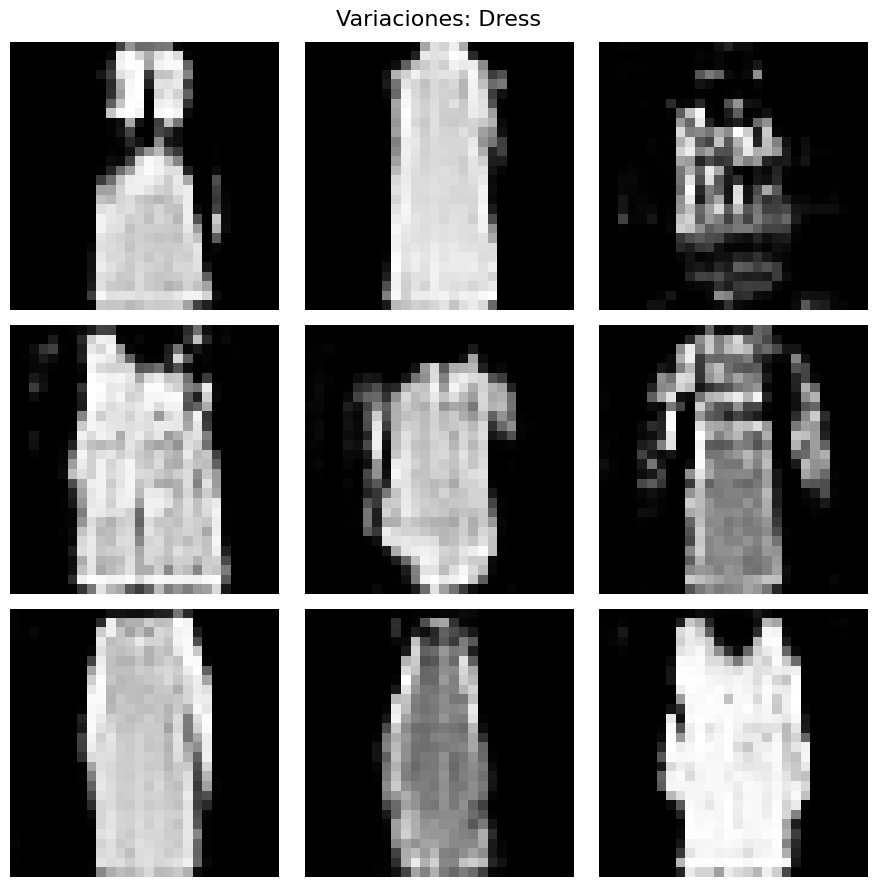

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/sneaker_samples.png


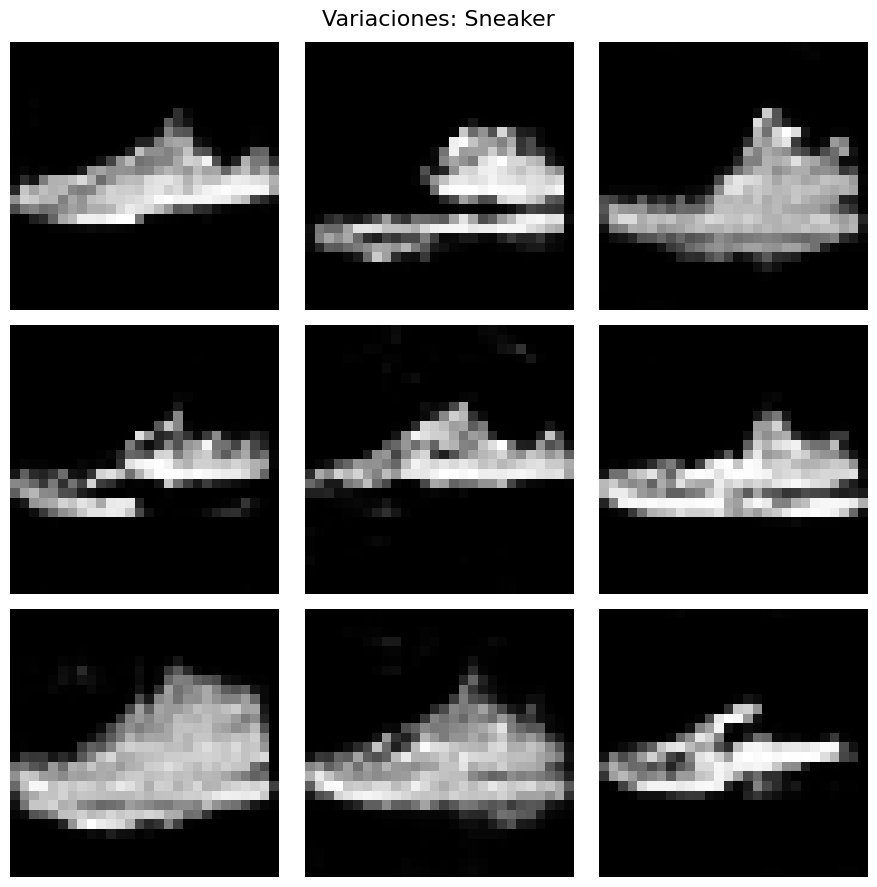

In [ ]:
#@title Generar prendas específicas prueba
generate_clothing_samples(generator, 'Dress', 9, save=True)
generate_clothing_samples(generator, 'Sneaker', 9, save=True)

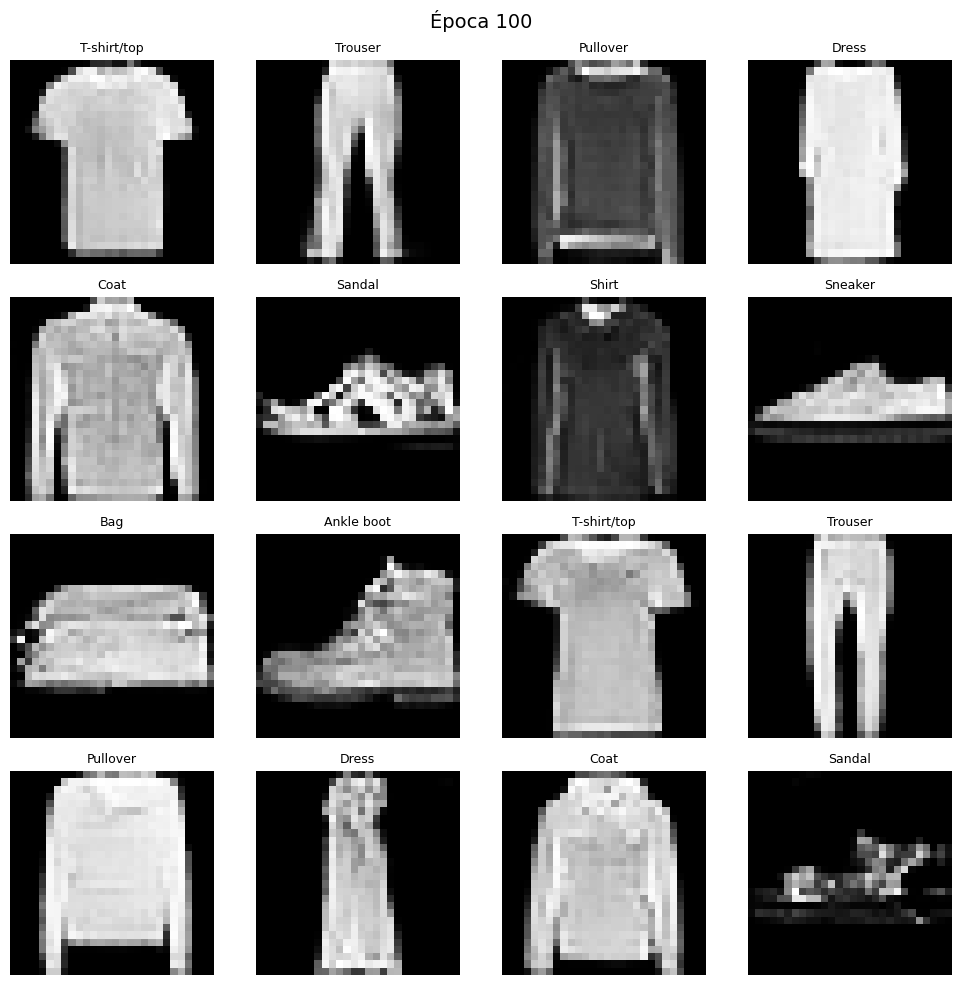

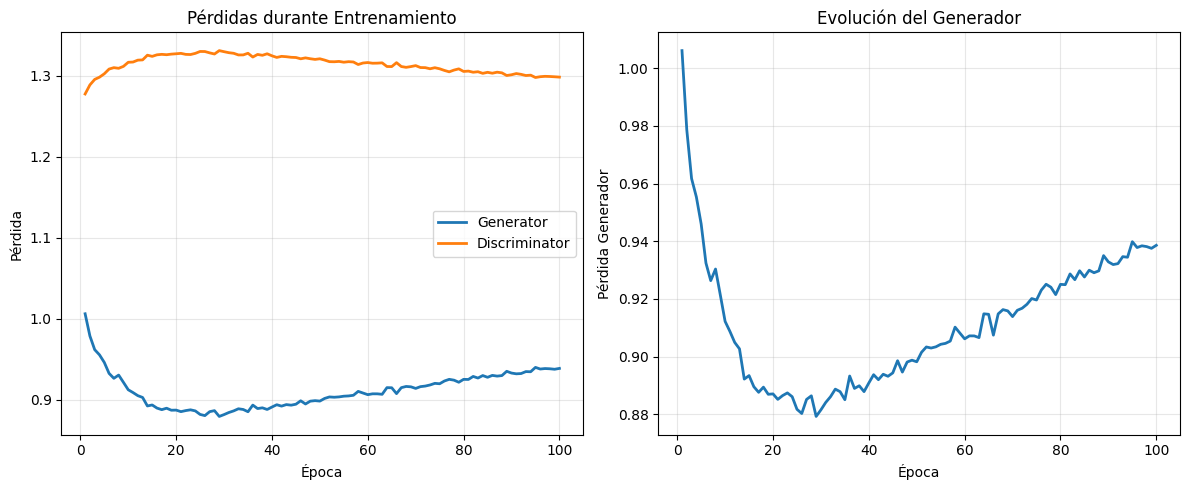

In [ ]:
#@title Entrenamiento completo

history = train(train_dataset, epochs=100, save_every=5, checkpoint_every=15)




In [ ]:
#@title Ver resultados entrenamiento completo
create_image_explorer()


interactive(children=(IntSlider(value=0, description='Época:', max=23), Output()), _dom_classes=('widget-inter…

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/ankle boot_samples.png


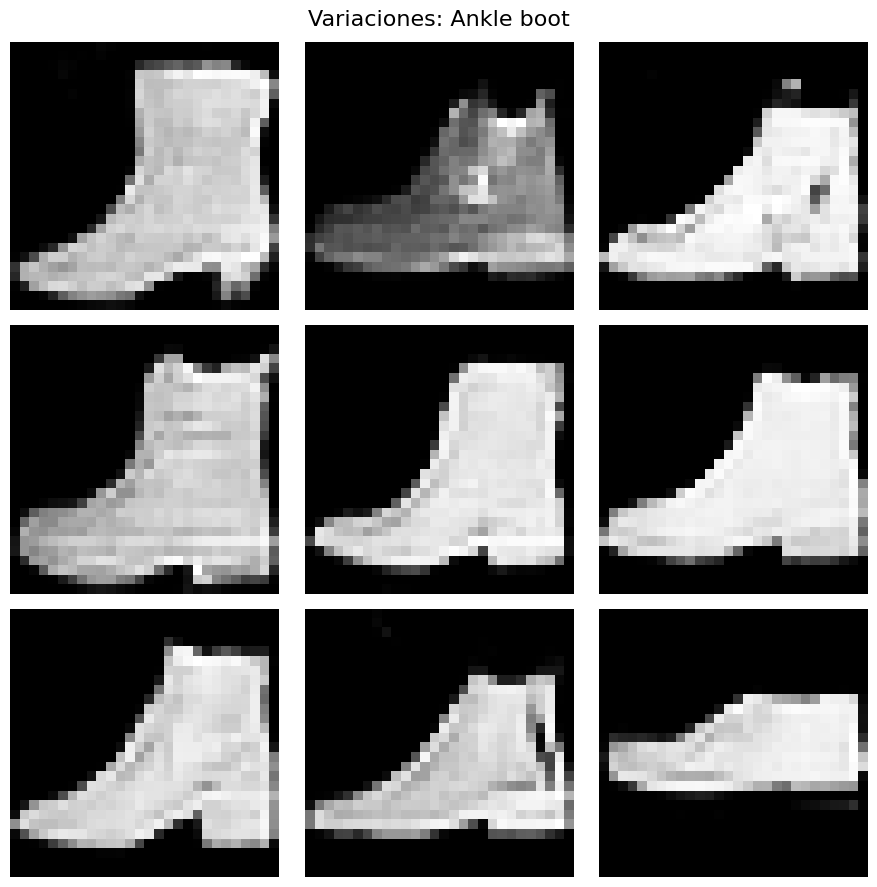

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/pullover_samples.png


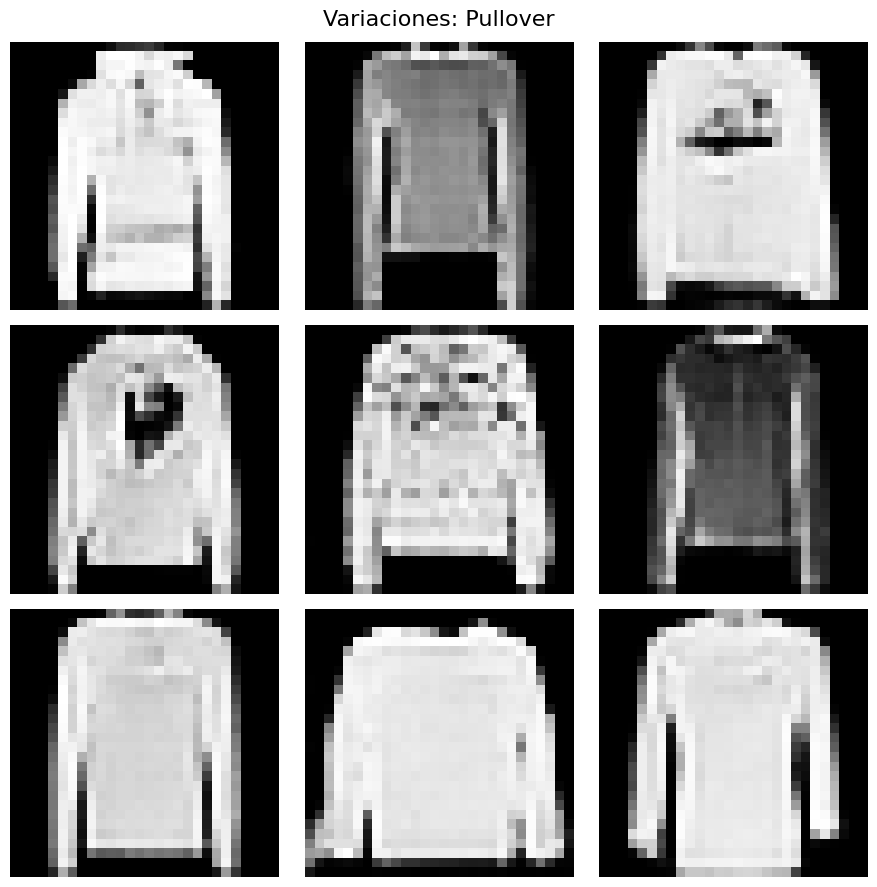

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/t-shirt_top_samples.png


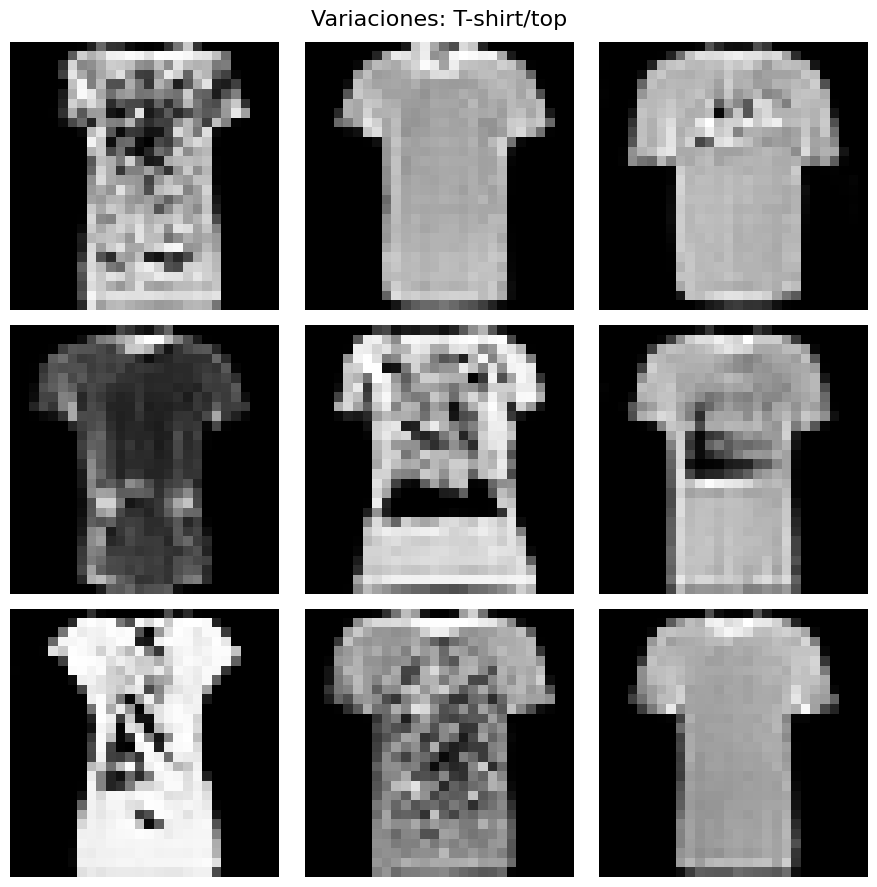

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/trouser_samples.png


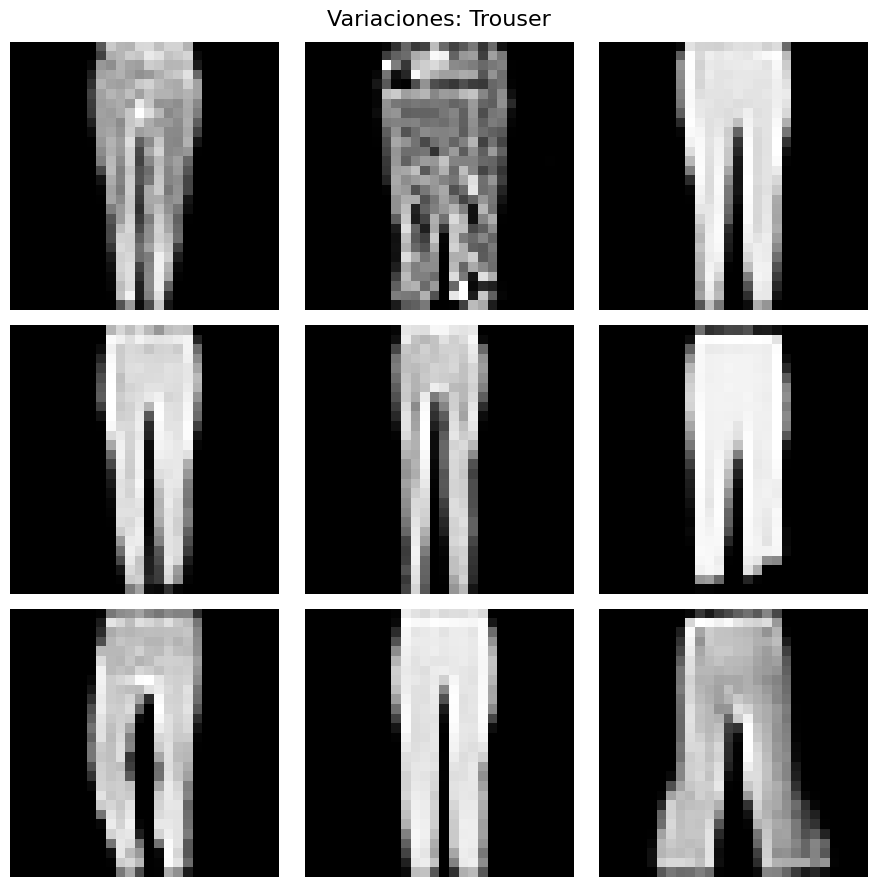

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/dress_samples.png


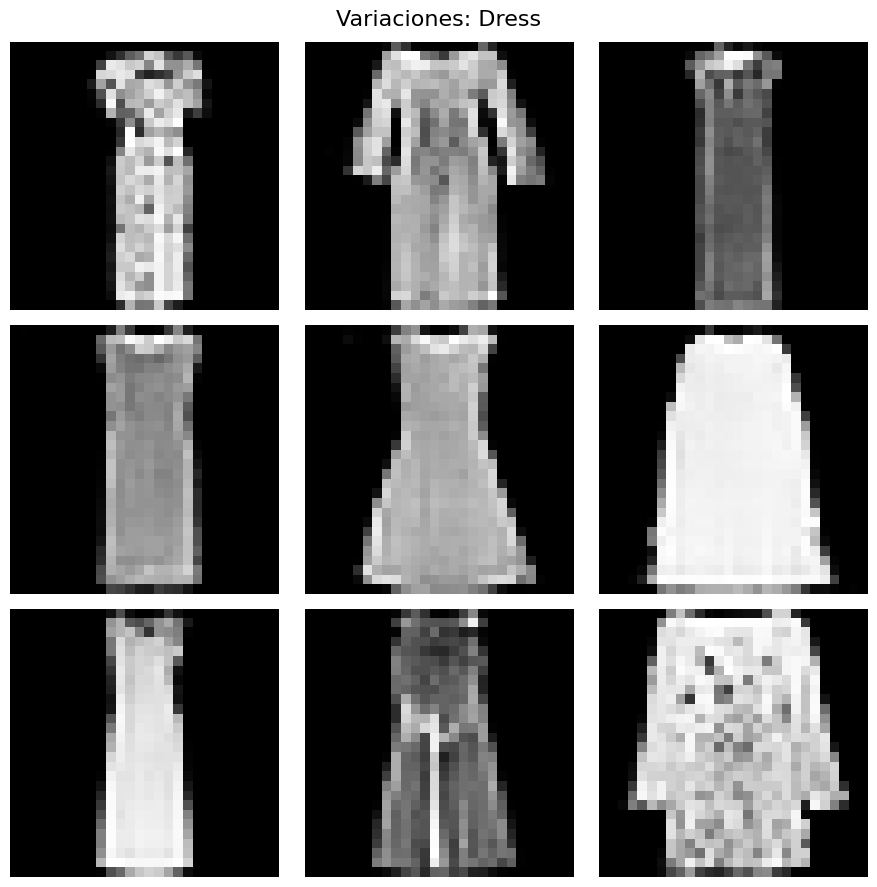

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/coat_samples.png


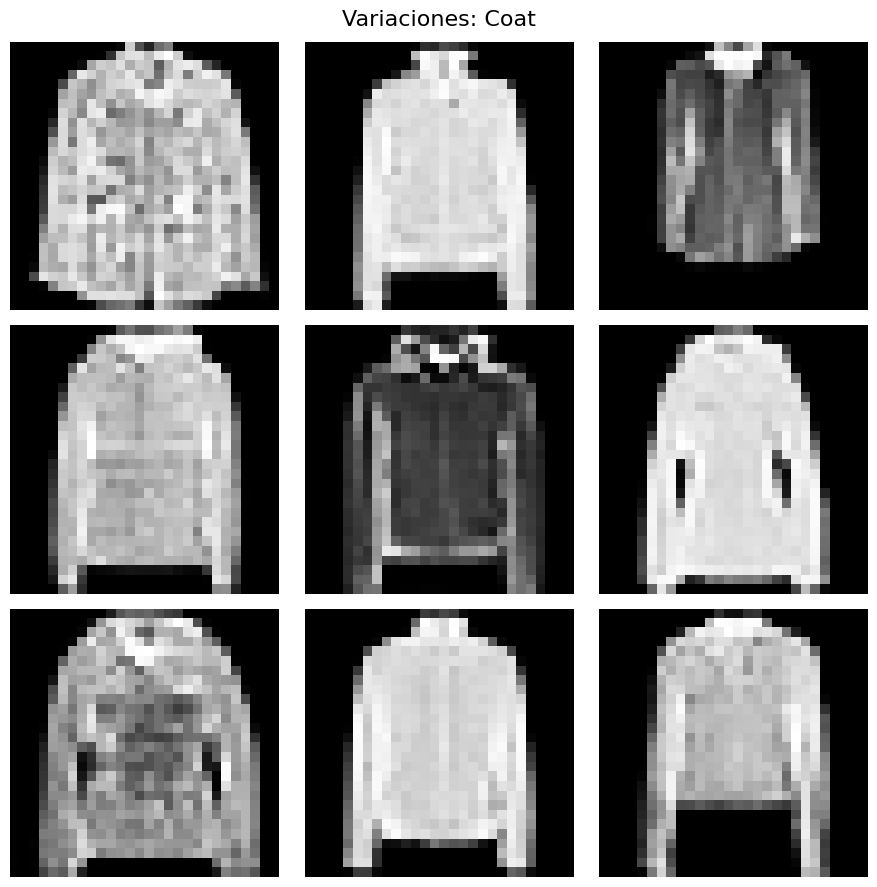

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/sandal_samples.png


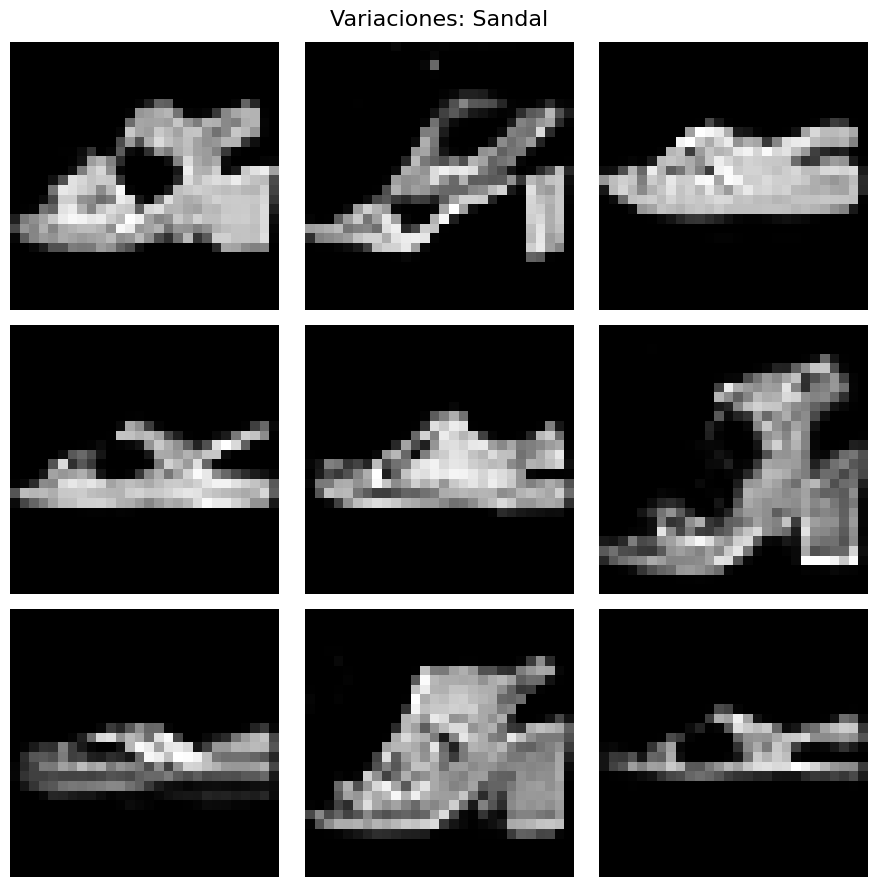

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/shirt_samples.png


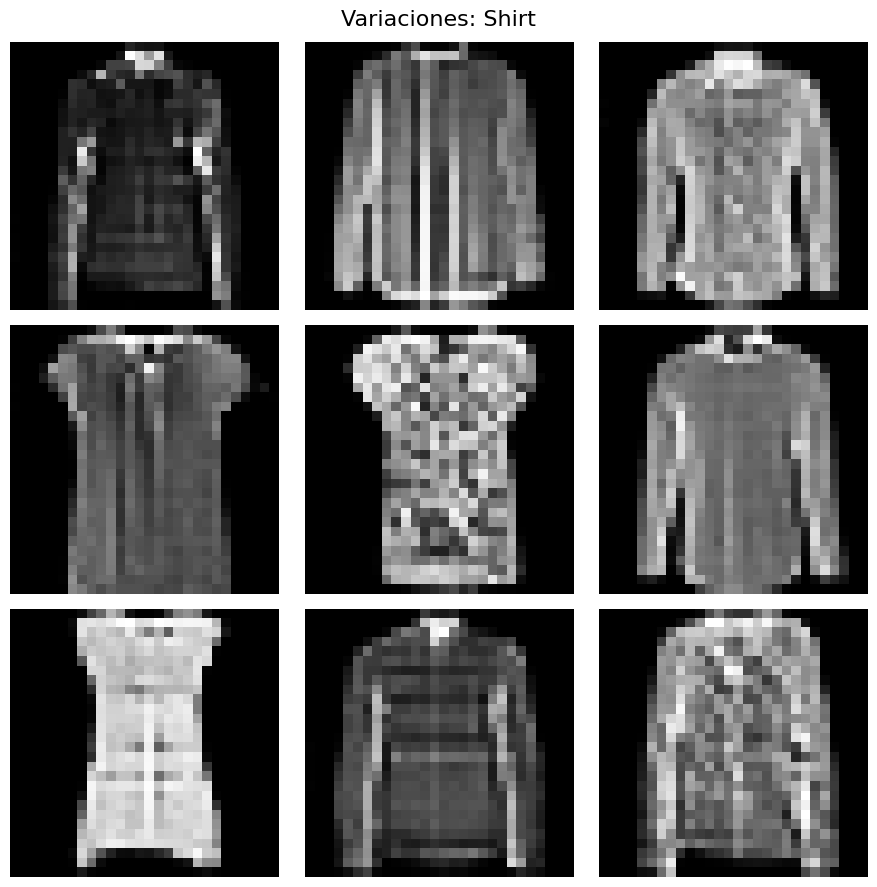

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/sneaker_samples.png


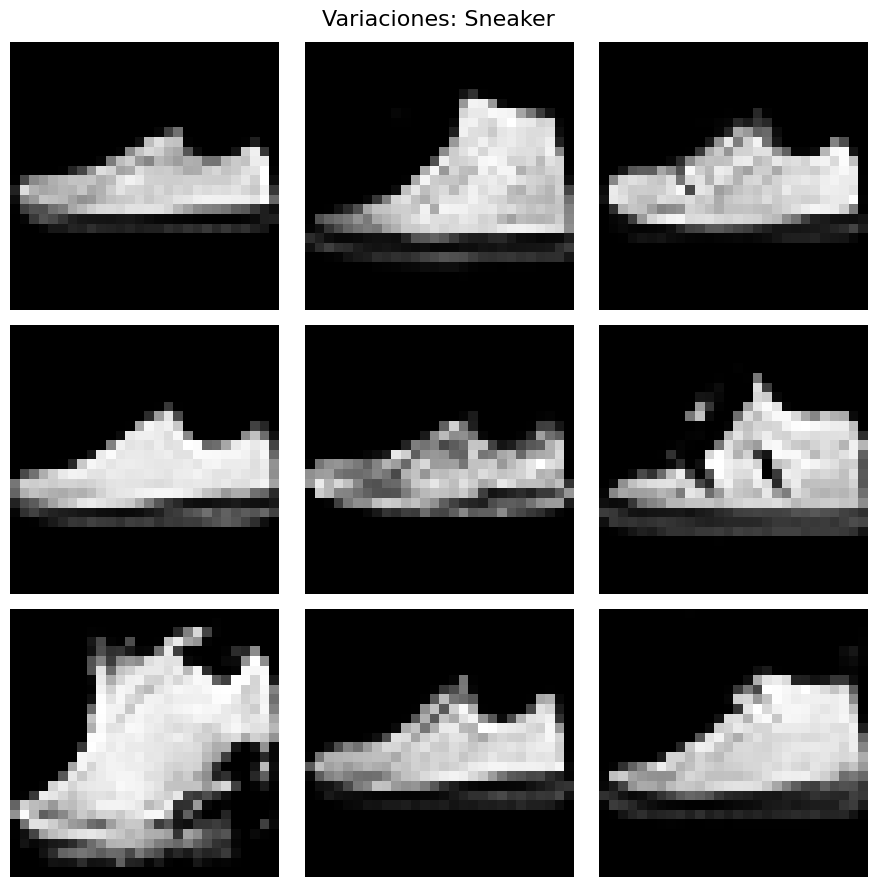

✓ Guardado: /content/drive/My Drive/imgs/cgan_samples/bag_samples.png


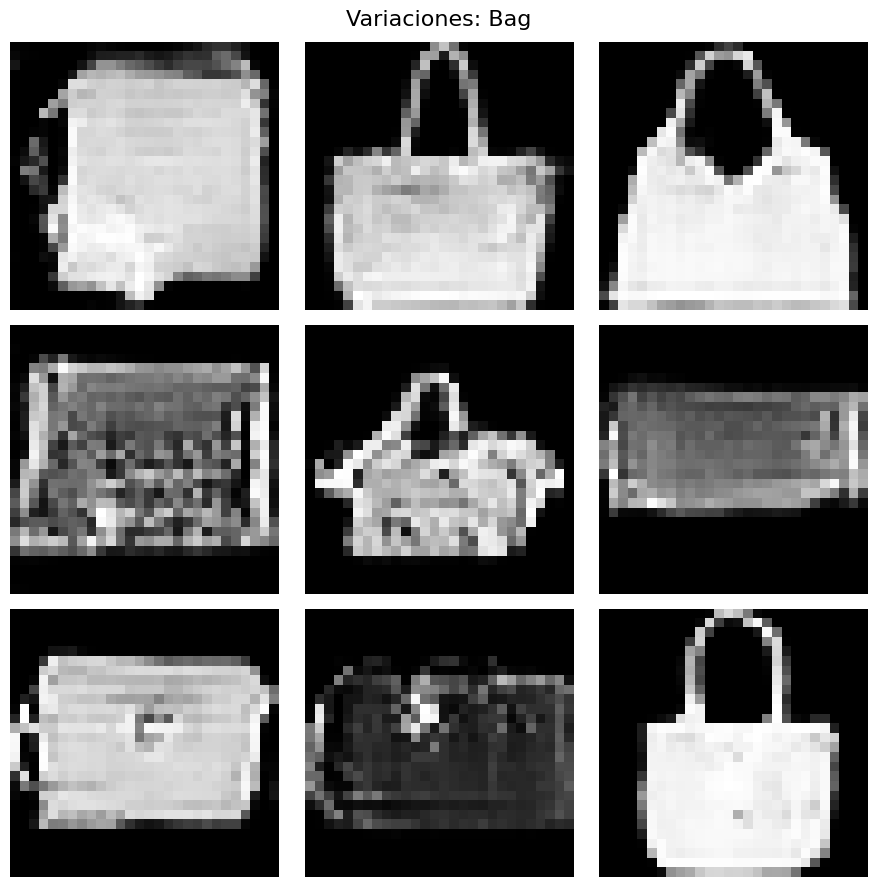

In [ ]:
#@title Generar prendas específicas Entrenamiento completo

generate_clothing_samples(generator, 'Ankle boot', 9, save=True)
generate_clothing_samples(generator, 'Pullover', 9, save=True)
generate_clothing_samples(generator, 'T-shirt/top', 9, save=True)
generate_clothing_samples(generator, 'Trouser', 9, save=True)
generate_clothing_samples(generator, 'Dress', 9, save=True)
generate_clothing_samples(generator, 'Coat', 9, save=True)
generate_clothing_samples(generator, 'Sandal', 9, save=True)
generate_clothing_samples(generator, 'Shirt', 9, save=True)
generate_clothing_samples(generator, 'Sneaker', 9, save=True)
generate_clothing_samples(generator, 'Bag', 9, save=True)
